In [1]:
import re

def split_into_chunks(text, max_words=50):
    # Split text into paragraphs
    paragraphs = re.split(r"\n+", text)
    chunks = []

    for para in paragraphs:
        para = para.strip()
        if not para:
            continue
        # Simple word tokenization using split
        words = para.split()

        # Break into chunks
        for i in range(0, len(words), max_words):
            chunk = " ".join(words[i:i+max_words])
            if len(chunk.split()) > 5:  # keep only meaningful chunks
                chunks.append(chunk)
    return chunks


In [2]:
import zipfile

# path to your zipped dataset
zip_path = "speeches_data/InauguralSpeeches.zip"

# extract contents
with zipfile.ZipFile(zip_path, 'r') as z:
    z.extractall("speeches_data")

# check what’s inside
import os
os.listdir("speeches_data")


['InauguralSpeeches.zip',
 'speeches_clean.csv',
 'InauguralSpeeches',
 '__MACOSX']

In [3]:
# president_years[(president, speech_num)] = year
president_years = {
    ("GeorgeWashington", "1"): 1789,
    ("GeorgeWashington", "2"): 1793,
    ("JohnAdams", "1"): 1797,
    ("ThomasJefferson", "1"): 1801,
    ("ThomasJefferson", "2"): 1805,
    ("JamesMadison", "1"): 1809,
    ("JamesMadison", "2"): 1813,
    ("JamesMonroe", "1"): 1817,
    ("JamesMonroe", "2"): 1821,
    ("JohnQuincyAdams", "1"): 1825,
    ("AndrewJackson", "1"): 1829,
    ("AndrewJackson", "2"): 1833,
    ("MartinVanBuren", "1"): 1837,
    ("WilliamHenryHarrison", "1"): 1841,
    ("JamesKPolk", "1"): 1845,
    ("ZacharyTaylor", "1"): 1849,
    ("FranklinPierce", "1"): 1853,
    ("JamesBuchanan", "1"): 1857,
    ("AbrahamLincoln", "1"): 1861,
    ("AbrahamLincoln", "2"): 1865,
    ("UlyssesSGrant", "1"): 1869,
    ("UlyssesSGrant", "2"): 1873,
    ("RutherfordBHays", "1"): 1877,
    ("JamesAGarfield", "1"): 1881,
    ("GroverCleveland", "1"): 1885,
    ("BenjaminHarrison", "1"): 1889,
    ("GroverCleveland", "2"): 1893,
    ("WilliamMcKinley", "1"): 1897,
    ("WilliamMcKinley", "2"): 1901,
    ("TheodoreRoosevelt", "1"): 1905,
    ("WilliamHowardTaft", "1"): 1909,
    ("WoodrowWilson", "1"): 1913,
    ("WoodrowWilson", "2"): 1917,
    ("WarrenGHarding", "1"): 1921,
    ("CalvinCoolidge", "1"): 1925,
    ("HerbertHoover", "1"): 1929,
    ("FranklinDRoosevelt", "1"): 1933,
    ("FranklinDRoosevelt", "2"): 1937,
    ("FranklinDRoosevelt", "3"): 1941,
    ("FranklinDRoosevelt", "4"): 1945,
    ("HarrySTruman", "1"): 1949,
    ("DwightDEisenhower", "1"): 1953,
    ("DwightDEisenhower", "2"): 1957,
    ("JohnFKennedy", "1"): 1961,
    ("LyndonBJohnson", "1"): 1965,
    ("RichardNixon", "1"): 1969,
    ("RichardNixon", "2"): 1973,
    ("JimmyCarter", "1"): 1977,
    ("RonaldReagan", "1"): 1981,
    ("RonaldReagan", "2"): 1985,
    ("GeorgeBush", "1"): 1989,
    ("BillClinton", "1"): 1993,
    ("BillClinton", "2"): 1997,
    ("GeorgeWBush", "1"): 2001,
    ("GeorgeWBush", "2"): 2005,
    ("BarackObama", "1"): 2009,
    ("BarackObama", "2"): 2013,
    ("DonaldTrump", "1"): 2017,
    ("JoeBiden", "1"): 2021,
    ("GroverCleveland-I", "1"): 1885,
    ("GroverCleveland-II", "2"): 1893,
    ("WilliamJClinton", "1"): 1993,
    ("WilliamJClinton", "2"): 1997,
    ("JamesGarfield", "1"): 1881,
    ("RutherfordBHayes", "1"): 1877,
    ("MartinvanBuren", "1"): 1837,
    ("DonaldJTrump", "1"): 2017,
}


In [4]:
import os
import pandas as pd
import re

speech_dir = "speeches_data/InauguralSpeeches"

data = []
for filename in os.listdir(speech_dir):
    if filename.endswith(".txt"):
        with open(os.path.join(speech_dir, filename), "r", encoding="utf-8") as f:
            text = f.read()

        base = filename.replace("inaug", "").replace(".txt", "")

        # Extract year if present
        match = re.search(r"\d{4}", base)
        if match:
            year = int(match.group())
            speech_num = base.split("-")[-1] if "-" in base else "1"
            president = None  # unknown from filename
        else:
            # If no year, assume format: PresidentName-SpeechNum
            if "-" in base:
                president, speech_num = base.rsplit("-", 1)
            else:
                president, speech_num = base, "1"

            president = president.strip()
            year = president_years.get((president, speech_num), None)

        data.append({
            "filename": filename,
            "president": president,
            "speech_num": speech_num,
            "year": year,
            "speech": text
        })

df = pd.DataFrame(data)
print(df.head())

                        filename           president speech_num  year  \
0  inaugGroverCleveland-II-2.txt  GroverCleveland-II          2  1893   
1       inaugJamesBuchanan-1.txt       JamesBuchanan          1  1857   
2         inaugBarackObama-2.txt         BarackObama          2  2013   
3     inaugWilliamMcKinley-2.txt     WilliamMcKinley          2  1901   
4     inaugWilliamJClinton-2.txt     WilliamJClinton          2  1997   

                                              speech  
0   My Fellow-Citizens:In obedience of the mandat...  
1   Fellow-Citizens:I appear before you this day ...  
2   Thank you. Thank you so much. Vice President ...  
3   My Fellow-Citizens:When we assembled here on ...  
4   My fellow citizens, at this last Presidential...  


In [5]:
df.to_csv("speeches_data/speeches_clean.csv", index=False)

In [6]:
#nan_year_rows = df[df["year"].isna()]
#print(nan_year_rows)

In [7]:
chunk_data = []
for _, row in df.iterrows():
    chunks = split_into_chunks(row["speech"], max_words=100)
    for i, chunk in enumerate(chunks):
        chunk_data.append({
            "year": row["year"],
            "president": row["president"],
            "speech_num": row["speech_num"],
            "chunk_id": f"{row['filename']}_chunk{i}",
            "speech_chunk": chunk.lower()
        })

df_chunks = pd.DataFrame(chunk_data)
print(df_chunks.head())
print("Total chunks:", len(df_chunks))
df_chunks.to_csv("chunks.csv", index=False)



   year           president speech_num                              chunk_id  \
0  1893  GroverCleveland-II          2  inaugGroverCleveland-II-2.txt_chunk0   
1  1893  GroverCleveland-II          2  inaugGroverCleveland-II-2.txt_chunk1   
2  1893  GroverCleveland-II          2  inaugGroverCleveland-II-2.txt_chunk2   
3  1893  GroverCleveland-II          2  inaugGroverCleveland-II-2.txt_chunk3   
4  1893  GroverCleveland-II          2  inaugGroverCleveland-II-2.txt_chunk4   

                                        speech_chunk  
0  my fellow-citizens:in obedience of the mandate...  
1  refer to the existence of certain conditions a...  
2  of life and rejoices in the hardihood of const...  
3  at once arouse to activity the most enlightene...  
4  from intolerance or passion, and our judgments...  
Total chunks: 1398


In [8]:
from sklearn.feature_extraction.text import CountVectorizer
from bertopic import BERTopic
from umap import UMAP
from hdbscan import HDBSCAN

# --- 1. Custom vectorizer ---
vectorizer_model = CountVectorizer(stop_words="english", min_df=2)

# --- 2. UMAP and HDBSCAN for dimensionality reduction & clustering ---
umap_model = UMAP(n_neighbors=5, n_components=5, min_dist=0.0, metric='cosine',random_state=42)
hdbscan_model = HDBSCAN(min_cluster_size=5, min_samples=2, metric='euclidean', cluster_selection_method='eom',prediction_data=True)

# --- 3. Initialize BERTopic ---
topic_model = BERTopic(
    umap_model=umap_model,
    hdbscan_model=hdbscan_model,
    vectorizer_model=vectorizer_model,
    verbose=True
)

# --- 4. Fit BERTopic on the speech chunks ---
docs = df_chunks["speech_chunk"].tolist()  # use chunks, not full speeches
topics, probs = topic_model.fit_transform(docs)

# ---------- Save trained model ----------
topic_model.save("model_folder/bertopic_presidents")
print("✅ Model trained and saved as 'bertopic_presidents'")

2025-11-10 18:58:16,339 - BERTopic - Embedding - Transforming documents to embeddings.


Batches:   0%|          | 0/44 [00:00<?, ?it/s]

2025-11-10 18:58:21,504 - BERTopic - Embedding - Completed ✓
2025-11-10 18:58:21,505 - BERTopic - Dimensionality - Fitting the dimensionality reduction algorithm
2025-11-10 18:58:25,490 - BERTopic - Dimensionality - Completed ✓
2025-11-10 18:58:25,490 - BERTopic - Cluster - Start clustering the reduced embeddings
2025-11-10 18:58:25,511 - BERTopic - Cluster - Completed ✓
2025-11-10 18:58:25,513 - BERTopic - Representation - Fine-tuning topics using representation models.
2025-11-10 18:58:25,576 - BERTopic - Representation - Completed ✓
2025-11-10 18:58:25,667 - BERTopic - WARNING: When you use `pickle` to save/load a BERTopic model,please make sure that the environments in which you saveand load the model are **exactly** the same. The version of BERTopic,its dependencies, and python need to remain the same.


✅ Model trained and saved as 'bertopic_presidents'


In [9]:
topic_model.visualize_topics()

In [10]:
topic_model.visualize_barchart()

In [11]:
topic_model.visualize_hierarchy()

In [12]:
# Get topic info from BERTopic
topic_info = topic_model.get_topic_info()
total_chunks = len(df_chunks)  # number of chunks

table = []

for _, row in topic_info.iterrows():
    topic_id = row["Topic"]
    count = row["Count"]
    perc = (count / total_chunks) * 100

    if topic_id == -1:
        # Label outliers explicitly
        topic_name = "Outliers"
        topic_def = "Not related to other topics"
    else:
        top_words = topic_model.get_topic(topic_id)
        if top_words:
            topic_name = ", ".join([w for w, _ in top_words[:3]])
            topic_def = f"Mainly about {topic_name}"
        else:
            topic_name = "Unknown"
            topic_def = "No representative words"

    table.append([topic_id, topic_name, topic_def, f"{perc:.1f}%"])

# Create a summary DataFrame
df_topics = pd.DataFrame(
    table,
    columns=["Topic", "Name", "Topic Definition", "Percentage of Chunks"]
)

print(df_topics)


     Topic                                   Name  \
0       -1                               Outliers   
1        0                    america, bless, god   
2        1                 liberty, freedom, know   
3        2                     america, jobs, new   
4        3                 revenue, loans, public   
..     ...                                    ...   
104    103                     prayer, im, escape   
105    104  ideals, aspirations, constitutionally   
106    105          thirteen, population, greater   
107    106                      gain, pass, truth   
108    107                 seas, currents, wished   

                                      Topic Definition Percentage of Chunks  
0                          Not related to other topics                18.1%  
1                     Mainly about america, bless, god                 3.7%  
2                  Mainly about liberty, freedom, know                 2.4%  
3                      Mainly about america, jobs, 

In [ ]:
from openai import OpenAI
key = "YOUR_API_KEY"

def summarize_economy(text, year, president):
    prompt = f"""
    You are analyzing U.S. presidential inaugural speeches.
    Extract and summarize how the topic of *economy* is discussed in this speech
    ({president}, {year}). Focus on economic themes like trade, taxation, growth, jobs,
    industry, commerce, and fiscal policy. Provide 2–3 sentences.
    """
    response = client.chat.completions.create(
        model="gpt-4o-mini",
        messages=[{"role": "user", "content": prompt + "\n\n" + text[:1500]}] # send first ~1500 chars
    )
    return response.choices[0].message.content



In [14]:
economy_keywords = [
    "economy", "economic", "commerce", "industry", "trade",
    "business", "jobs", "growth", "prosperity", "tax", "labor"
]

df["economy_mentions"] = df["speech"].str.lower().apply(
    lambda x: sum(word in x for word in economy_keywords)
)



# Group speeches into 20-year bins
df["period"] = (df["year"] // 20) * 20

trend = df.groupby("period")["economy_mentions"].mean().reset_index()



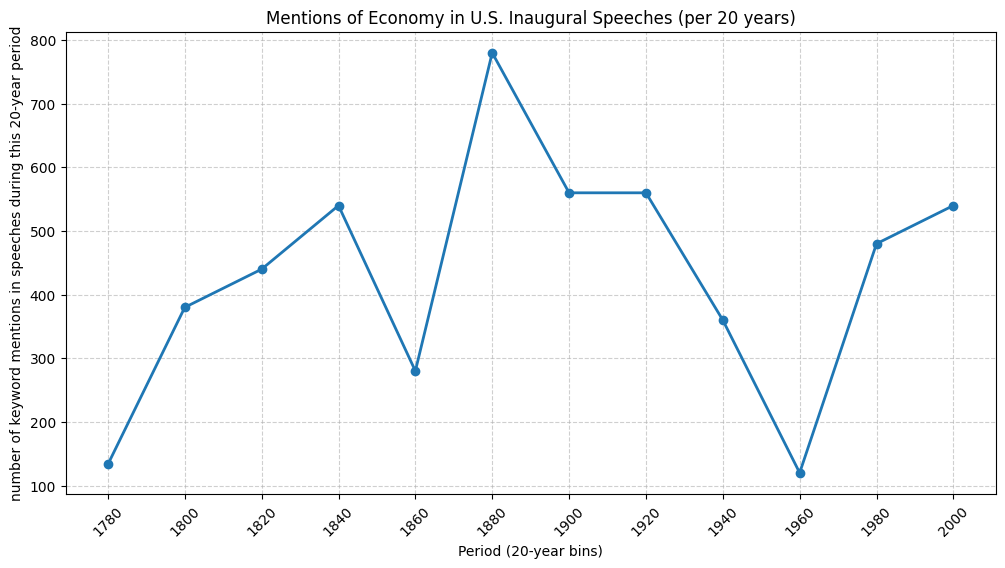

In [15]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12,6))
plt.plot(trend["period"], trend["economy_mentions"]*100, marker="o", linewidth=2)
plt.title("Mentions of Economy in U.S. Inaugural Speeches (per 20 years)")
plt.xlabel("Period (20-year bins)")
plt.ylabel("number of keyword mentions in speeches during this 20-year period")
plt.xticks(trend["period"], rotation=45)
plt.grid(True, linestyle="--", alpha=0.6)
plt.show()


In [16]:
summaries = []
for period, group in df.groupby("period"):
    combined_text = " ".join(group["speech"].tolist())
    summary = summarize_economy(combined_text, f"{period}s", "Multiple Presidents")
    summaries.append({"period": period, "summary": summary})

df_summaries = pd.DataFrame(summaries)

pd.set_option("display.max_colwidth", None)
df_summaries


,period,summary
0,1780,"In the early U.S. presidential inaugural speeches, the economy is often a focal point interwoven with themes of independence and governance. The discourse typically acknowledges the necessity of establishing a stable economic framework within a newly independent nation, emphasizing cooperation among states to foster trade and promote commerce while avoiding the pitfalls of foreign dependence. Moreover, the speeches allude to the importance of fiscal policy that supports growth and job creation, highlighting the need for a government structure that encourages industrial development and addresses economic challenges resulting from political dissension."
1,1800,"In this inaugural speech, the president emphasizes the extraordinary economic prosperity of the nation, highlighting the contrast between the recent record of growth and the difficulties currently faced. He acknowledges the remarkable improvements in agriculture, commerce, and manufacturing, attributing these successes to the benefits of republican governance and peaceful relations with other nations. The tone suggests a commitment to maintaining this economic momentum while addressing the pressing challenges ahead."
2,1820,"In this speech from the 1820s, the president reflects on the importance of maintaining a stable foreign policy, which indirectly supports economic themes such as trade and commerce. By promoting peace with other nations and ensuring justice, the administration aims to create an environment conducive to economic growth and stability. Although the speech does not delve deeply into specifics like taxation or fiscal policy, the emphasis on a successful foreign policy suggests a foundational approach to sustaining and enhancing the nation’s economic prosperity."
3,1840,"In this inaugural speech, the discussion of the economy is indirectly framed through the themes of unity and governance, suggesting that a strong, stable government is crucial for economic prosperity. The emphasis on restoring harmony and friendship among the states implies that political stability is essential for fostering commerce and industry. Additionally, the call for support to uphold just measures hints at a commitment to sound fiscal policy that would encourage growth and job creation, reinforcing the notion that effective governance is intertwined with economic well-being."
4,1860,"In this inaugural speech, the President emphasizes the necessity of restoring harmony and public credit as essential steps toward economic recovery following a period of internal conflict. He underlines the importance of fostering commerce and the arts of peace to drive growth and stability, suggesting a vision of economic recovery closely tied to national unity and responsible governance. By advocating for a government that reflects republican ideals, the President conveys a belief that a stable economy will flourish under a system that values representation and the needs of the populace."
5,1880,"In this inaugural speech, the president highlights the impressive growth and expansion of the nation, underscoring the economic vitality and industriousness of the American people. However, he also warns of underlying threats that could undermine this progress, suggesting that vigilance is necessary to protect the nation's economic integrity and ensure continued prosperity. The mention of ""thrift and enterprise"" reflects a recognition of the importance of commerce and industry as pillars of economic strength, indicating a commitment to safeguarding these attributes against potential challenges."
6,1900,"In this inaugural speech, the topic of economy is addressed through a narrative of recovery and optimism following a period of financial distress. The speaker highlights a transition from a situation of inadequate Treasury receipts and high taxation to a surplus fund and a $41 million reduction in taxes, emphasizing fiscal responsibility and improved financial health. Furthermore, the